08 does left / right matter? testing why horizontal flip hurt

in notebook 07 the only clear effect was a negative one: training with horizontally mirrored clips (variant E) cost **8.9 balanced accuracy and 8.3 AUC** (neutral vs negative), on all 3 seeds. a flip should keep the label (a mirrored scoliosis child is still a scoliosis child), so why does it hurt? two explanations are possible:

1. **the side is part of the signal.** in adolescent idiopathic scoliosis most thoracic curves bend to the right, so "which shoulder / hip is higher, which side is wider" is not random. a model trained on real children can use the side, and a mirrored child looks like a rare (left-curve) child. flip then teaches the model to ignore something useful.
2. **flip just makes training harder.** with only 500 iterations, a harder task (two versions of every child) can simply be under-trained, and the side has nothing to do with it.

the two explanations predict different things for a model trained **without** flip: under (1) the mirrored test children should look different to it (scores change, ranking drops), under (2) it shouldn't care much. so here i train the plain variant B of notebook 07 (ScoNet-MT + LA loss, no flip) with the same 3 seeds, this time **saving the weights**, and test every child twice: normal and mirrored, with exactly the same clips. in step 4 i also look at the silhouettes themselves, without any model: is there a left / right difference between the classes in the raw data?

in step 1 i set things up, in step 2 i retrain B (and check that it matches notebook 07), in step 3 i do the mirror test, in step 4 the silhouette asymmetry, in step 5 i check if it comes from the body or from the recording, and step 6 is the analysis.

step 1: setup

In [1]:
import sys
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
MODEL_DIR = os.path.join('output', 'models')
NB07_RUNS = os.path.join('..', '07_robust_pipeline', 'output', 'runs')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


same shared code as before. the trained weights go to `output/models/` (about 25 MB per model), so the mirror test and any later test on these models doesn't need a retrain.

step 2: retrain variant B and check it against notebook 07

the children are exactly the ones of notebook 07 (train 160 / 20 / 20, val 20 / 20 / 20, test 40 / 40 / 40, same seeds), and the model is variant B: ScoNet-MT with the logit-adjusted loss, natural sampler, no flip. i use B and not A because B doesn't need a big tau (its val tau was 0-0.15), so the mirror test isn't mixed up with the border, and B was as good as C and D.

because i train with the same seeds as in notebook 07, the result *should* be the same. but the GPU isn't fully deterministic (fp16 and cuDNN choose kernels by speed, and atomic adds in the backward pass are done in a random order), so i check how close the new scores are to the saved ones of notebook 07: the correlation of the test scores and how many children get a different prediction.

In [2]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 160, 'neutral': 20, 'positive': 20}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))
train_subjects = set(it['subject'] for it in mini_train)
rest_of_train = [s for s in split['TRAIN_SET'] if s not in train_subjects]
mini_val = load_items(pick_children(rest_of_train, {'negative': 20, 'neutral': 20, 'positive': 20}, seed=1))

mini_counts = np.array([sum(it['label'] == c for it in mini_train) for c in range(3)])
mini_prior = torch.tensor(mini_counts / mini_counts.sum(), dtype=torch.float32, device=DEVICE)
LOG_PRIOR = np.log(mini_counts / mini_counts.sum())
SEEDS = [0, 1, 2]


def loss_la(out, labels, pids):
    adjusted = out['logits'].float() + (torch.log(mini_prior) / 16).view(1, 3, 1)
    return triplet_loss(out['embed'], pids) + ce_loss(adjusted, labels)


@torch.no_grad()
def predict_clips(model, items, seed=0, mirror=False):
    # 10 random clips of 16 frames per child, scores averaged (same as notebook 07).
    # mirror=True: exactly the same clips, flipped left <-> right
    model = model.to(DEVICE).eval()
    rng = np.random.default_rng(seed)
    ys, scores = [], []
    for it in items:
        seq = it['seq']
        clips = np.stack([sil_transform(seq[np.sort(rng.choice(len(seq), MINI['frames'], replace=False))])
                          for _ in range(MINI['test_clips'])])
        if mirror:
            clips = clips[..., ::-1].copy()
        with torch.autocast(device_type=DEVICE, enabled=DEVICE == 'cuda'):
            out = model(torch.tensor(clips).to(DEVICE))
        scores.append(out['logits'].float().cpu().numpy().mean(-1).mean(0))
        ys.append(it['label'])
    return np.array(ys), 16 * np.array(scores)


models = {}
for seed in SEEDS:
    path = os.path.join(MODEL_DIR, f'B_seed{seed}.pt')
    set_seed(seed)
    model = ScoNetMT()
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location='cpu'))
    else:
        t0 = time.time()
        load_gaitbase_backbone(model.backbone)
        train_mini(model, mini_train, loss_fn=loss_la, balanced=False, seed=seed, verbose=False)
        torch.save(model.state_dict(), path)
        print(f'seed {seed}: trained in {time.time() - t0:.0f}s')
    models[seed] = model.to(DEVICE).eval()

print()
print('same seed, retrained vs notebook 07:')
for seed in SEEDS:
    old = np.load(os.path.join(NB07_RUNS, f'B_seed{seed}.npz'))
    y, z = predict_clips(models[seed], mini_test, seed=0)
    r = np.corrcoef(z.ravel(), old['z_test_c0'].ravel())[0, 1]
    changed = (z.argmax(1) != old['z_test_c0'].argmax(1)).sum()
    print(f'seed {seed} | score correlation {r:.3f} | children with another prediction (tau = 0): {changed} / {len(y)}'
          f' | bal now {metrics(y, z.argmax(1))["bal"]:.1f} vs nb07 {metrics(y, old["z_test_c0"].argmax(1))["bal"]:.1f}')


same seed, retrained vs notebook 07:


seed 0 | score correlation 1.000 | children with another prediction (tau = 0): 0 / 120 | bal now 64.2 vs nb07 64.2


seed 1 | score correlation 1.000 | children with another prediction (tau = 0): 0 / 120 | bal now 70.0 vs nb07 70.0


seed 2 | score correlation 1.000 | children with another prediction (tau = 0): 0 / 120 | bal now 66.7 vs nb07 66.7


**the retrained models are identical to notebook 07**: score correlation 1.000 and 0 of 120 children with another prediction on all 3 seeds (balanced 64.2 / 70.0 / 66.7, exactly as before). so in this setup the same seed gives the same model, and the seed spread of notebook 07 is real seed-to-seed variation, not GPU randomness. good news for reproducibility: a mini result can be re-created exactly from its seed.

step 3: the mirror test

for every model and every test child i compute the class scores twice, on the **same 10 clips**: normal, and mirrored left <-> right. then i look at four things:

1. **balanced accuracy and AUCs**, normal vs mirrored (at tau = 0, B doesn't need a tau). if the side doesn't matter, they should be the same.
2. **how many predictions flip**: children whose predicted class is different on the mirrored clips.
3. **the scoliosis score per class**: `s = max(z_neu, z_pos) - z_neg` (how much "not negative" the child looks), normal minus mirrored, averaged per class. if mirroring makes **scoliosis children look healthier** (s goes down for neutral / positive) but doesn't change the negatives, the model uses a side-specific scoliosis cue.
4. **test-time flip averaging**: the mean of the normal and the mirrored scores. if the side were noise, averaging two views should help (like averaging more clips), if the side is signal it should hurt.

In [3]:
def pair_aucs(z, y):
    s_nn = z[:, 1] - z[:, 0]
    s_sn = np.maximum(z[:, 1], z[:, 2]) - z[:, 0]
    return 100 * auc(s_nn[y == 1], s_nn[y == 0]), 100 * auc(s_sn[y > 0], s_sn[y == 0])


def scoliosis_score(z):
    return np.maximum(z[:, 1], z[:, 2]) - z[:, 0]


mirror = {}
rows = {'normal': [], 'mirrored': [], 'average of both': []}
for seed in SEEDS:
    y, z_n = predict_clips(models[seed], mini_test, seed=0, mirror=False)
    _, z_m = predict_clips(models[seed], mini_test, seed=0, mirror=True)
    mirror[seed] = (y, z_n, z_m)
    for name, z in [('normal', z_n), ('mirrored', z_m), ('average of both', (z_n + z_m) / 2)]:
        m = metrics(y, z.argmax(1))
        m['auc_nn'], m['auc_sn'] = pair_aucs(z, y)
        rows[name].append(m)

print('test 40 / 40 / 40, variant B, tau = 0, mean +- std over 3 seeds')
keys = ['bal', 'Sen', 'rec_neu', 'rec_pos', 'auc_nn', 'auc_sn']
print(f'{"":18s}' + ''.join(f'{k:>14s}' for k in keys))
for name, ms in rows.items():
    print(f'{name:18s}' + ''.join(f'{np.mean([m[k] for m in ms]):8.1f} +-{np.std([m[k] for m in ms]):4.1f}' for k in keys))

print()
for seed in SEEDS:
    y, z_n, z_m = mirror[seed]
    changed = z_n.argmax(1) != z_m.argmax(1)
    print(f'seed {seed} | predictions that change when mirrored: {changed.sum():3d} / {len(y)}'
          + ''.join(f' | {LABEL_NAMES[c]} {changed[y == c].sum():2d}' for c in range(3)))

test 40 / 40 / 40, variant B, tau = 0, mean +- std over 3 seeds
                             bal           Sen       rec_neu       rec_pos        auc_nn        auc_sn
normal                66.9 +- 2.4    77.5 +- 4.1    55.8 +- 2.4    67.5 +- 3.5    80.5 +- 2.2    85.7 +- 2.0
mirrored              33.1 +- 0.4    99.2 +- 1.2     0.0 +- 0.0     0.0 +- 0.0    52.8 +- 2.9    41.9 +- 1.3
average of both       40.0 +- 0.7    99.2 +- 1.2    18.3 +- 2.4     2.5 +- 0.0    72.9 +- 2.1    68.1 +- 2.4

seed 0 | predictions that change when mirrored:  62 / 120 | negative  8 | neutral 24 | positive 30
seed 1 | predictions that change when mirrored:  65 / 120 | negative  7 | neutral 27 | positive 31
seed 2 | predictions that change when mirrored:  73 / 120 | negative 11 | neutral 29 | positive 33


**mirroring the test children destroys the model completely: balanced accuracy 66.9 -> 33.1, every child becomes negative** (Sen 99.2, neutral 0.0, positive 0.0) on all 3 seeds. the ranking breaks too: neutral vs negative AUC 80.5 -> 52.8 (chance), and scoliosis vs negative **85.7 -> 41.9, below chance**, so on mirrored clips the healthy children look *more* scoliotic than the scoliotic ones. **62-73 of 120 predictions change, and almost all of them are neutral (24-29 of 40) and positive (30-33 of 40) children**; only 7-11 negatives change.

**test-time averaging of normal and mirrored scores also hurts** (40.0 balanced, AUC 72.9 / 68.1), so the mirrored view is not "another view of the same child", it's a different, misleading input.

so explanation (2) of the intro ("flip only makes training harder") is out: a model that never saw a flip treats left and right as completely different. the side is the main thing this model uses to call scoliosis.

scoliosis score s = max(z_neu, z_pos) - z_neg: mean of (normal - mirrored) per class
positive = the child looks MORE like scoliosis on the real (not mirrored) clips
                      negative               neutral              positive
seed 0        1.27 ( 98% > 0)      2.15 (100% > 0)      3.10 (100% > 0)
seed 1        1.14 (100% > 0)      2.13 (100% > 0)      2.84 (100% > 0)
seed 2        1.30 ( 92% > 0)      2.38 (100% > 0)      3.16 (100% > 0)


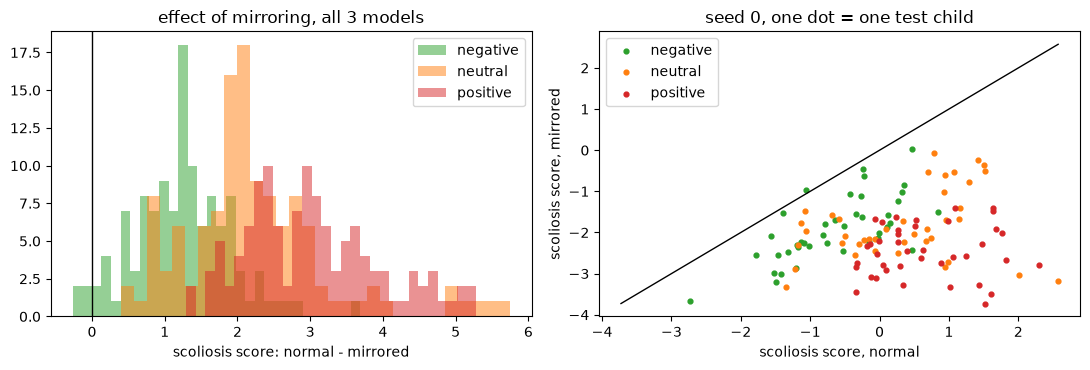

In [4]:
print('scoliosis score s = max(z_neu, z_pos) - z_neg: mean of (normal - mirrored) per class')
print('positive = the child looks MORE like scoliosis on the real (not mirrored) clips')
print(f'{"":8s}' + ''.join(f'{n:>22s}' for n in LABEL_NAMES))
all_delta = {c: [] for c in range(3)}
for seed in SEEDS:
    y, z_n, z_m = mirror[seed]
    d = scoliosis_score(z_n) - scoliosis_score(z_m)
    line = f'seed {seed}  '
    for c in range(3):
        all_delta[c].append(d[y == c])
        frac = 100 * (d[y == c] > 0).mean()
        line += f'{d[y == c].mean():10.2f} ({frac:3.0f}% > 0)'
    print(line)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for c, color in zip(range(3), ['tab:green', 'tab:orange', 'tab:red']):
    d = np.concatenate(all_delta[c])
    ax[0].hist(d, bins=30, alpha=0.5, color=color, label=LABEL_NAMES[c])
ax[0].axvline(0, color='black', lw=1)
ax[0].set_xlabel('scoliosis score: normal - mirrored')
ax[0].set_title('effect of mirroring, all 3 models')
ax[0].legend()
y, z_n, z_m = mirror[0]
for c, color in zip(range(3), ['tab:green', 'tab:orange', 'tab:red']):
    ax[1].scatter(scoliosis_score(z_n)[y == c], scoliosis_score(z_m)[y == c], s=12, color=color, label=LABEL_NAMES[c])
lim = [min(scoliosis_score(z_n).min(), scoliosis_score(z_m).min()), max(scoliosis_score(z_n).max(), scoliosis_score(z_m).max())]
ax[1].plot(lim, lim, color='black', lw=1)
ax[1].set_xlabel('scoliosis score, normal')
ax[1].set_ylabel('scoliosis score, mirrored')
ax[1].set_title('seed 0, one dot = one test child')
ax[1].legend()
save_and_show(fig, '01_mirror_scores.png')

**the scoliosis score is higher on the real clips than on the mirrored ones for practically every child: 100% of neutral and positive children on all seeds, and 92-100% of the negatives.** the drop is graded by class: about 1.2 for negative, 2.1-2.4 for neutral and 2.8-3.2 for positive. so the model has learned "one particular side = scoliosis", and the more scoliotic the class, the more of that side cue the real clips have. the histogram shows three shifted bumps all on the right of 0, and in the scatter (seed 0) every child lies under the diagonal: mirrored always looks healthier.

step 4: left / right in the silhouettes themselves

now without any model: is there a left / right difference in the raw silhouettes, and is it different between the classes?

for every frame i find the **center column** of the body (the mean x of all white pixels), and in 4 horizontal bands (head 0-10, shoulders / upper torso 10-24, lower torso / hips 24-36, legs 36-64, in rows of the 64-high silhouette) i measure

`asym = (white pixels right of the center - white pixels left of the center) / all white pixels in the band`

so 0 = symmetric, > 0 = more body on the image-right side. per child i keep two numbers per band: the **signed** mean over all frames (a consistent side), and the **mean of |asym|** (how asymmetric, whatever the side).

one complication: Scoliosis1K children walk **towards and away from** the camera. a child with a high right shoulder shows it on the image-right side from behind, and on the image-left side from the front. so the signed mean over a whole sequence can cancel out even if the child is asymmetric. the |asym| doesn't have that problem. i can't separate front and back frames from the silhouette alone (notebook 04 only separated side / turning frames by width), so the signed number is a weak test.

In [5]:
BANDS = {'head': (0, 10), 'upper torso': (10, 24), 'hips': (24, 36), 'legs': (36, 64)}


def frame_asymmetry(sil):
    # sil [64, 44] in 0..1 -> {band: signed asymmetry} around the body center column
    cols = np.arange(sil.shape[1])
    total = sil.sum()
    if total < 1:
        return None
    cx = (sil.sum(0) * cols).sum() / total
    out = {}
    for name, (r0, r1) in BANDS.items():
        band = sil[r0:r1]
        mass = band.sum()
        if mass < 1:
            out[name] = 0.0
            continue
        right = band[:, cols > cx].sum()
        left = band[:, cols < cx].sum()
        out[name] = (right - left) / mass
    return out


def child_asymmetry(item):
    sils = sil_transform(item['seq'])
    signed = {b: [] for b in BANDS}
    for sil in sils:
        a = frame_asymmetry(sil)
        if a is None:
            continue
        for b in BANDS:
            signed[b].append(a[b])
    return ({b: float(np.mean(v)) for b, v in signed.items()},
            {b: float(np.mean(np.abs(v))) for b, v in signed.items()})


asym_signed, asym_abs, asym_y = [], [], []
for it in mini_train + mini_val + mini_test:
    s, a = child_asymmetry(it)
    asym_signed.append([s[b] for b in BANDS])
    asym_abs.append([a[b] for b in BANDS])
    asym_y.append(it['label'])
asym_signed, asym_abs, asym_y = np.array(asym_signed), np.array(asym_abs), np.array(asym_y)
print('children used:', len(asym_y), '| per class:', [int((asym_y == c).sum()) for c in range(3)])
print()
print('signed asymmetry (x100), mean +- std per class')
print(f'{"":12s}' + ''.join(f'{b:>18s}' for b in BANDS))
for c in range(3):
    v = 100 * asym_signed[asym_y == c]
    print(f'{LABEL_NAMES[c]:12s}' + ''.join(f'{m:9.2f} +-{s:5.2f}' for m, s in zip(v.mean(0), v.std(0))))
print()
print('|asymmetry| (x100), mean per class, and AUC scoliosis (neu + pos) vs negative')
print(f'{"":12s}' + ''.join(f'{b:>18s}' for b in BANDS))
for c in range(3):
    v = 100 * asym_abs[asym_y == c]
    print(f'{LABEL_NAMES[c]:12s}' + ''.join(f'{m:18.2f}' for m in v.mean(0)))
print(f'{"AUC":12s}' + ''.join(f'{100 * auc(asym_abs[asym_y > 0, i], asym_abs[asym_y == 0, i]):18.1f}'
                                  for i in range(len(BANDS))))
print(f'{"AUC signed":12s}' + ''.join(f'{100 * auc(asym_signed[asym_y > 0, i], asym_signed[asym_y == 0, i]):18.1f}'
                                         for i in range(len(BANDS))))

children used: 380 | per class: [220, 80, 80]

signed asymmetry (x100), mean +- std per class
                          head       upper torso              hips              legs
negative        13.22 +- 9.29     2.59 +- 1.61     0.45 +- 0.89    -5.15 +- 3.45
neutral         21.20 +- 5.46     3.96 +- 1.21     0.36 +- 0.75    -8.20 +- 2.33
positive        21.20 +- 9.57     4.73 +- 1.01     0.83 +- 0.95   -10.26 +- 3.28

|asymmetry| (x100), mean per class, and AUC scoliosis (neu + pos) vs negative
                          head       upper torso              hips              legs
negative                 31.13              6.62              5.10             13.28
neutral                  33.31              6.90              5.07             14.71
positive                 34.96              7.11              5.28             15.04
AUC                       59.8              62.4              54.1              71.4
AUC signed                76.2              81.2              55.5        

**the raw silhouettes already show it, without any model.** the signed asymmetry is not 0 for anyone: the head is shifted to the image-right (+13 to +21) and the legs to the image-left (-5 to -10) in every class, so all children lean the same way in the image (or are filmed from the same slightly-off angle). but **the lean is bigger for neutral and positive**: upper torso +2.6 (negative) vs +4.0 (neutral) vs +4.7 (positive), legs -5.2 vs -8.2 vs -10.3.

**the signed upper-torso asymmetry alone, one hand-made number per child, separates scoliosis from negative with AUC 81.2**, and the legs with 82.2 (shown as 17.8 because the sign is reversed). my trained mini model reaches 85.7. the hips don't separate (55.5). **the side-free |asymmetry| is much weaker (AUC 54-71)**, so what separates the classes is a **consistent direction**, not "how asymmetric" a child is.

neutral and positive have exactly the same head value (21.20), while the upper torso and legs are graded (neutral between negative and positive). a real curve would give exactly that graded pattern in the torso, but the identical head value doesn't fit severity well.

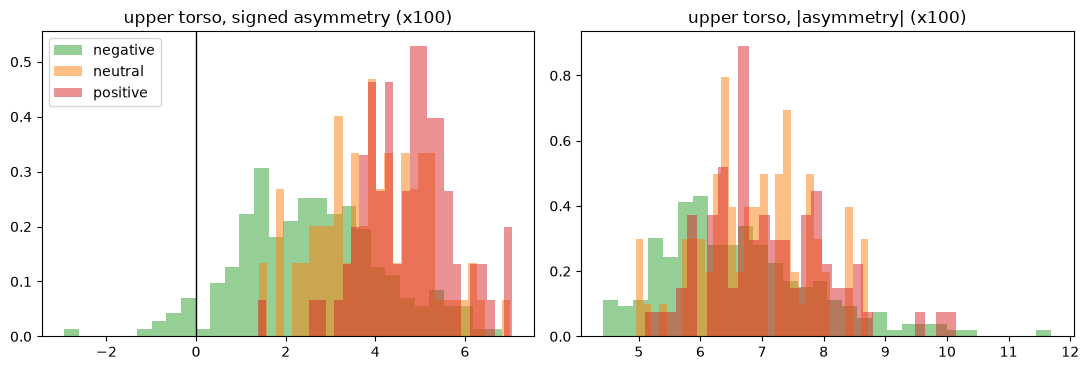

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
i = list(BANDS).index('upper torso')
for c, color in zip(range(3), ['tab:green', 'tab:orange', 'tab:red']):
    ax[0].hist(100 * asym_signed[asym_y == c, i], bins=30, alpha=0.5, color=color, label=LABEL_NAMES[c], density=True)
    ax[1].hist(100 * asym_abs[asym_y == c, i], bins=30, alpha=0.5, color=color, label=LABEL_NAMES[c], density=True)
ax[0].axvline(0, color='black', lw=1)
ax[0].set_title('upper torso, signed asymmetry (x100)')
ax[1].set_title('upper torso, |asymmetry| (x100)')
ax[0].legend()
save_and_show(fig, '02_silhouette_asymmetry.png')

in the upper torso, the signed histograms of neutral and positive sit clearly right of the negatives, while the |asymmetry| histograms of the three classes almost overlap. the class information is in the direction.

step 5: the body or the camera?

step 4 found a left / right difference between the classes, but there's a catch in how Scoliosis1K is numbered: **the class is fully determined by the subject id**. positive = ids 0-492, negative = 493-1292, neutral = 1293-1492. so the children of one class were probably recorded (or processed) as one block, and anything that changes between recording sessions (camera position, walking line, cropping) is mixed up with the class. a left / right offset of the silhouette is exactly the kind of thing a camera position changes.

two checks:

1. **asymmetry per block of 100 ids** (every 3rd child of the 1:1:8 split, so ~34 per block). if the asymmetry is a body property, all negative blocks should look alike, and different from the scoliosis blocks. if it's the session, negative blocks will differ from each other as much as the classes do.
2. **does the model use it on healthy children?** inside the **negative test children only** (no scoliosis at all), i correlate the model's scoliosis score with the signed upper-torso asymmetry. a negative child has no curve, so if the model still calls the more asymmetric negatives "more scoliotic", it reacts to the asymmetry itself, whatever causes it.

In [7]:
from scipy.stats import spearmanr      # disclaimer: library function for the rank correlation

all_subjects = sorted(split['TRAIN_SET'] + split['TEST_SET'], key=int)
print(f'{"ids":>11s} {"class":9s} {"n":>3s} {"head":>7s} {"upper torso":>12s} {"legs":>7s}')
block_rows = []
for lo in range(0, 1500, 100):
    sub = [x for x in all_subjects if lo <= int(x) < lo + 100][::3]
    if not sub:
        continue
    vals = []
    for x in sub:
        signed, _ = child_asymmetry({'seq': load_seq(x)})
        vals.append([signed[b] for b in ['head', 'upper torso', 'legs']])
    vals = 100 * np.array(vals)
    cls = subject_class(sub[0])
    block_rows.append((lo, cls, vals.mean(0)))
    print(f'{lo:4d}-{lo + 99:<6d} {cls:9s} {len(sub):3d} {vals[:, 0].mean():7.1f} {vals[:, 1].mean():12.2f} {vals[:, 2].mean():7.1f}')

print()
test_signed = []
for it in mini_test:
    signed, _ = child_asymmetry(it)
    test_signed.append(signed['upper torso'])
test_signed = np.array(test_signed)
for seed in SEEDS:
    y, z_n, _ = mirror[seed]
    sc = scoliosis_score(z_n)
    neg = y == 0
    print(f'seed {seed} | negative test children only: spearman(scoliosis score, signed upper torso asymmetry) = '
          f'{spearmanr(sc[neg], test_signed[neg])[0]:.2f} | all test children: {spearmanr(sc, test_signed)[0]:.2f}')

        ids class       n    head  upper torso    legs


   0-99     positive   34    18.0         4.38    -9.7


 100-199    positive   34    20.2         4.77   -10.3


 200-299    positive   34    22.7         4.95   -10.3


 300-399    positive   34    24.0         5.34    -9.7


 400-499    positive   34    22.4         4.02    -9.5


... (7 outputs left out)

1200-1299   negative   34    10.6         2.40    -4.1


1300-1399   neutral    34    19.9         3.91    -7.3


1400-1499   neutral    31    22.1         4.43    -9.3



seed 0 | negative test children only: spearman(scoliosis score, signed upper torso asymmetry) = 0.32 | all test children: 0.44
seed 1 | negative test children only: spearman(scoliosis score, signed upper torso asymmetry) = 0.42 | all test children: 0.48
seed 2 | negative test children only: spearman(scoliosis score, signed upper torso asymmetry) = 0.44 | all test children: 0.47


**the negative blocks differ from each other as much as the classes do.** across the 8 negative blocks the upper-torso asymmetry goes from 1.71 (ids 700-799) to **3.67 (ids 800-899)**, and the head from 6.4 to 18.8. the block 800-899 is all negative children, and it looks like a neutral block (neutral: 3.91-4.43 torso, 19.9-22.1 head). in the positive blocks (0-499) the values stay high everywhere (4.0-5.3). so a large part of the asymmetry changes with the **recording block**, not with the diagnosis, which is what a session effect (camera position, walking line) would do.

**and the model uses it on healthy children: inside the negative test children only, the scoliosis score correlates with the signed upper-torso asymmetry with rho 0.32 / 0.42 / 0.44** (3 seeds). these children have no curve, so the model calls a negative child "more scoliotic" when its silhouette leans more in the image. over all test children rho is 0.44-0.48.

this doesn't prove that the asymmetry is *only* camera: real scoliosis can shift the trunk, the graded torso values (negative < neutral < positive) fit a real effect, and some "negatives" may have a mild shift. but in this dataset **class, id block and recording are confounded**, and the model's strongest cue is one that also varies between recording blocks of healthy children.

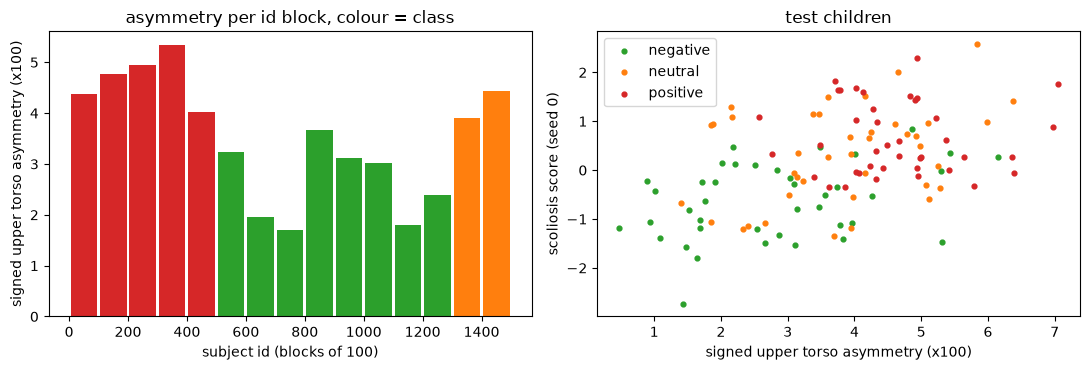

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {'negative': 'tab:green', 'neutral': 'tab:orange', 'positive': 'tab:red'}
for lo, cls, v in block_rows:
    ax[0].bar(lo + 50, v[1], width=90, color=colors[cls])
ax[0].set_xlabel('subject id (blocks of 100)')
ax[0].set_ylabel('signed upper torso asymmetry (x100)')
ax[0].set_title('asymmetry per id block, colour = class')
y, z_n, _ = mirror[0]
sc = scoliosis_score(z_n)
for c in range(3):
    ax[1].scatter(100 * test_signed[y == c], sc[y == c], s=12, color=colors[LABEL_NAMES[c]], label=LABEL_NAMES[c])
ax[1].set_xlabel('signed upper torso asymmetry (x100)')
ax[1].set_ylabel('scoliosis score (seed 0)')
ax[1].set_title('test children')
ax[1].legend()
save_and_show(fig, '03_asymmetry_by_id.png')

the left plot shows the per-block bars: the green (negative) bars go up and down between ~1.7 and ~3.7, and the 800-899 bar is as high as the orange (neutral) ones. the right plot shows the score rising with the asymmetry inside each class, also inside the green negatives.

step 6: analysis

**1. why did flip hurt in notebook 07?**

because the model's main cue is direction-specific. a model trained without flip gives 33.1 balanced (everything negative) on mirrored test children instead of 66.9, and its scoliosis vs negative AUC goes from 85.7 to 41.9, below chance. training with flip forces the model to ignore the side, and then it loses its strongest cue (notebook 07: -8.9 balanced, -8.3 AUC).

**2. what is the cue?**

a consistent left / right lean of the silhouette in the image: head to the right, legs to the left, more so in neutral and positive. one number (signed upper-torso asymmetry) gives AUC 81.2 for scoliosis vs negative with no learning at all, close to the trained mini model (85.7). the side-free |asymmetry| is weak (54-71), so it's the direction that separates.

**3. is it the body or the recording?**

probably both, and this dataset can't separate them. for the body: the torso values are graded (2.6 / 4.0 / 4.7), like severity. for the recording: the class is fully set by the subject id (positive 0-492, negative 493-1292, neutral 1293-1492), the negative id blocks vary as much as the classes (torso 1.7 to 3.7, one negative block looks neutral), and the model scores healthy negatives as more scoliotic when they lean more (rho 0.32-0.44).

**4. what does this mean for ScoNet-MT, TG-MILNet and ScoliGaitX?**

they all train on the same data with the same id-to-class blocks, so they all could learn this cue, and none of them reports a mirror test or a check against the recording. a part of the accuracy of *all* methods on Scoliosis1K might come from a recording difference between the class blocks. this is a hypothesis for the full models; i tested it only on my mini models.

**5. what does it change about "robust"?**

a robust model should rely on a cue that is a property of the child, not of the recording session. a mirror test (does the decision depend on the side?) and a within-negative correlation with the image lean (does the score move for healthy children?) are cheap checks that can be run on any trained model, including the full ScoNet-MT 16k model.

**6. what are the limitations?**

- mini models only (500 iterations, 160 / 20 / 20 children, GaitBase init). the full ScoNet-MT could use the cue more or less.
- the asymmetry measure is simple: column center of mass, fixed row bands for a 64-high silhouette, no front / back separation, so a real shoulder difference can cancel between front and back frames.
- i don't have recording metadata (date, camera position), so "session effect" is an inference from the id blocks, not a proven fact.
- the id-block table uses every 3rd child (~34 per block).
- "negative" children in Scoliosis1K are screening negatives, so some might have a mild trunk shift.
- the right-curve clinical prior (most idiopathic thoracic curves are right-convex) is general knowledge, not checked on this dataset (there are no curve directions in the labels).

what can we absorb into the new architecture?

**never use horizontal flip** for Scoliosis1K: the side is the main cue, and flipping removes it (notebook 07: -8.9, here: mirrored test = 33.1).

more important, this changes what "robust" should mean for my paper. the strongest single finding of checkpoint_2 is now that **a one-number image lean already gives AUC 81 for scoliosis vs negative, and it also varies between id blocks of healthy children**. before i claim any architecture beats TG-MILNet or ScoliGaitX, i should run the **mirror test and the within-negative lean correlation on the full ScoNet-MT 16k model** (cheap, no training, the model is in checkpoint_1), and ideally a **"lean-corrected" test**: re-centre every silhouette so the body axis is vertical (or compare models on children matched by lean), and see how much accuracy is left. if the full model also collapses on mirrored input and its accuracy drops a lot after removing the lean, then a big part of every Scoliosis1K number is the recording, and a model that is robust to this (same accuracy with and without the lean) would be a real contribution that none of the three papers can claim.